# ML_1. Введение в машинное обучение

## 1.1. Пять примеров применения ML

| № | Пример | Что предсказывает модель | Польза от ML |
|---|--------|--------------------------|--------------|
| 1 | Спам-фильтр в почте | Спам письмо или нет | Писем миллиарды, правила вручную не написать, а спамеры быстро обходят фиксированные правила. Модель дообучается на новых примерах. |
| 2 | Рекомендации товаров, фильмов, музыки | Что понравится конкретному пользователю | Персональная подборка для миллионов людей сразу; растут продажи и время в сервисе. |
| 3 | Антифрод по банковским картам | Мошенническая операция или нет | Решение за миллисекунды по сотням признаков; меньше потерь у банка и клиентов. |
| 4 | Прогноз спроса на электроэнергию (или на такси) по часам | Нагрузка сети или число заказов | Точнее планируются мощности и ресурсы: меньше перерасхода и дефицита. |
| 5 | Автоматическая разметка фотографий | Набор тегов: "пляж", "собака", "закат" | Поиск по содержимому фото без ручной разметки миллиардов снимков. |

## 1.2. Классы задач

**Задачи из таблицы в теории.** Многие задачи можно поставить несколькими способами - в таблице главные варианты.

| № | Задача | Обучение | Постановка |
|---|--------|----------|------------|
| 1 | Цена дома | С учителем | Регрессия (цена - число). Классификация, если предсказывать ценовой сегмент |
| 2 | Вернёт ли клиент кредит | С учителем | Бинарная классификация (вернёт / не вернёт). Регрессия, если предсказывать сумму потерь банка |
| 3 | Когда пациенту принять лекарство | С учителем | Регрессия (через сколько часов принять). Классификация "принимать сейчас / нет" |
| 4 | Какое лекарство выбрать | С учителем | Многоклассовая классификация (одно лекарство из нескольких) |
| 5 | Сегмент клиентов для промо | С учителем и без | Классификация (откроет ли клиент рассылку) или регрессия (прирост прибыли). Без учителя: кластеризация клиентов; ассоциации - с какими товарами покупают товары из промо. Для нового бренда без истории продаж остаются методы без учителя |
| 6 | Брак на конвейере по фото | С учителем | Бинарная классификация (брак / не брак). Снижение размерности - сжать изображение в компактный набор признаков |
| 7 | Расстановка товаров на полке | С учителем и без | Регрессия (продажи или прибыль при данной расстановке). Ассоциативные правила: товары, которые покупают вместе, ставим рядом |
| 8 | Поиск сайтов по запросу | С учителем и без | Классификация (релевантен ли сайт запросу) или регрессия (оценка релевантности для ранжирования). Снижение размерности - компактные векторы текстов |
| 9 | Сегменты покупателей | Без учителя | Кластеризация. Снижение размерности - чтобы визуализировать сегменты |
| 10 | Аномалии трафика (DDoS) | Без учителя (с учителем, если есть разметка) | Поиск аномалий: кластеризация, запросы "непохожие на остальные". С разметкой атак - бинарная классификация |

По классам:
- **классификация**: 1, 2, 3, 4, 5, 6, 8, 10;
- **регрессия**: 1, 2, 3, 5, 7, 8;
- **кластеризация**: 5, 9, 10;
- **ассоциации**: 5, 7;
- **снижение размерности**: 6, 8, 9.

**Мои 5 примеров**

| № | Пример | Обучение | Постановка |
|---|--------|----------|------------|
| 1 | Спам-фильтр | С учителем | Бинарная классификация |
| 2 | Рекомендации | Без учителя и с учителем | Ассоциации ("с этим товаром покупают"), кластеризация похожих пользователей; классификация "кликнет / нет" или регрессия оценки |
| 3 | Антифрод | С учителем (без учителя, если нет разметки) | Бинарная классификация; поиск аномалий |
| 4 | Прогноз спроса | С учителем | Регрессия |
| 5 | Разметка фото | С учителем | Multilabel-классификация |

На практике классы комбинируют: например, перед кластеризацией часто снижают размерность.

## 1.3. Multiclass и multilabel

- **Multiclass** - у каждого объекта ровно один класс из C > 2 взаимоисключающих. Фрукт - яблоко, груша *или* банан.
- **Multilabel** - у объекта может быть сразу несколько меток (или ни одной). На одной фотографии одновременно "пляж", "собака" и "закат".

В multiclass модель выбирает один класс (вероятности классов в сумме дают 1). В multilabel ответ - вектор из C независимых "да / нет", по сути C бинарных классификаторов. Поэтому и метрики разные: accuracy для multiclass; hamming loss и F1 по меткам для multilabel.

## 1.4. Цены домов: классификация или регрессия?

Это **регрессия**: целевая переменная (цена) - вещественное число, а не метка класса.

Регрессию можно **свести к классификации**: разбить цену на интервалы ("дешёвые", "средние", "дорогие" или бины по 50 тыс.) и предсказывать номер интервала. Платим точностью: дома внутри одного интервала неразличимы, и ответ - интервал, а не число (можно отдавать его середину или медиану). Порядок классов при этом важен - ошибка "дешёвый → дорогой" хуже, чем "дешёвый → средний", - поэтому подходит порядковая (ordinal) классификация.

# 2. Introduction to Data Analysis

In [1]:
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import lightgbm as lgb
import scipy
import scipy.stats as st
import statsmodels
import statsmodels.api as sm
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

DATA_PATH = Path('data/train.json') 
INTEREST_CODES = {'low': 0, 'medium': 1, 'high': 2}

pd.set_option('display.max_columns', 30)
plt.rcParams.update({
    'figure.figsize': (8, 4),
    'axes.grid': True,
    'grid.color': '#e5e5e5',
    'grid.linewidth': 0.6,
    'axes.axisbelow': True,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
THOUSANDS = mticker.StrMethodFormatter('{x:,.0f}')


def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


def exact_linear_regression():
    if 'tol' in LinearRegression().get_params():
        return LinearRegression(tol=0)
    return LinearRegression()


print('python      ', sys.version.split()[0])
for lib in [np, pd, sklearn, lgb, scipy, statsmodels, matplotlib, sns]:
    print(f'{lib.__name__:12s}', lib.__version__)

python       3.14.4
numpy        2.5.3
pandas       3.0.6
sklearn      1.9.1
lightgbm     4.7.0
scipy        1.18.1
statsmodels  0.15.0
matplotlib   3.11.2
seaborn      0.13.2


## 2.1. Загрузка данных

In [2]:
df = pd.read_json(DATA_PATH)
df.head()

,bathrooms,bedrooms,building_id,created,description,display_address,features,latitude,listing_id,longitude,manager_id,photos,price,street_address,interest_level
4,1.0,1,8579a0b0d54db803821a35a4a615e97a,2016-06-16 05:55:27,Spacious 1 Bedroom 1 Bathroom in Williamsburg!...,145 Borinquen Place,"[Dining Room, Pre-War, Laundry in Building, Di...",40.7108,7170325,-73.9539,a10db4590843d78c784171a107bdacb4,[https://photos.renthop.com/2/7170325_3bb5ac84...,2400,145 Borinquen Place,medium
6,1.0,2,b8e75fc949a6cd8225b455648a951712,2016-06-01 05:44:33,BRAND NEW GUT RENOVATED TRUE 2 BEDROOMFind you...,East 44th,"[Doorman, Elevator, Laundry in Building, Dishw...",40.7513,7092344,-73.9722,955db33477af4f40004820b4aed804a0,[https://photos.renthop.com/2/7092344_7663c19a...,3800,230 East 44th,low
9,1.0,2,cd759a988b8f23924b5a2058d5ab2b49,2016-06-14 15:19:59,**FLEX 2 BEDROOM WITH FULL PRESSURIZED WALL**L...,East 56th Street,"[Doorman, Elevator, Laundry in Building, Laund...",40.7575,7158677,-73.9625,c8b10a317b766204f08e613cef4ce7a0,[https://photos.renthop.com/2/7158677_c897a134...,3495,405 East 56th Street,medium
10,1.5,3,53a5b119ba8f7b61d4e010512e0dfc85,2016-06-24 07:54:24,A Brand New 3 Bedroom 1.5 bath ApartmentEnjoy ...,Metropolitan Avenue,[],40.7145,7211212,-73.9425,5ba989232d0489da1b5f2c45f6688adc,[https://photos.renthop.com/2/7211212_1ed4542e...,3000,792 Metropolitan Avenue,medium
15,1.0,0,bfb9405149bfff42a92980b594c28234,2016-06-28 03:50:23,Over-sized Studio w abundant closets. Availabl...,East 34th Street,"[Doorman, Elevator, Fitness Center, Laundry in...",40.7439,7225292,-73.9743,2c3b41f588fbb5234d8a1e885a436cfa,[https://photos.renthop.com/2/7225292_901f1984...,2795,340 East 34th Street,low


## 2.2. Размер данных

In [3]:
print(f'Строк: {df.shape[0]}, столбцов: {df.shape[1]}')

Строк: 49352, столбцов: 15


**Ответ:** 49 352 строки (объявления) и 15 столбцов.

## 2.3. Столбцы и целевая переменная

In [4]:
df.columns.tolist()

['bathrooms',
 'bedrooms',
 'building_id',
 'created',
 'description',
 'display_address',
 'features',
 'latitude',
 'listing_id',
 'longitude',
 'manager_id',
 'photos',
 'price',
 'street_address',
 'interest_level']

**Ответ:** целевая переменная - `price`, месячная цена аренды в долларах: её мы предсказываем. В исходном соревновании Kaggle целевой была `interest_level`, но в этом проекте решаем регрессию цены.

## 2.4. Быстрый анализ: `info()`, `describe()`, `corr()`

In [5]:
df.info()

<class 'pandas.DataFrame'>
Index: 49352 entries, 4 to 124009
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   bathrooms        49352 non-null  float64
 1   bedrooms         49352 non-null  int64  
 2   building_id      49352 non-null  str    
 3   created          49352 non-null  str    
 4   description      49352 non-null  str    
 5   display_address  49352 non-null  str    
 6   features         49352 non-null  object 
 7   latitude         49352 non-null  float64
 8   listing_id       49352 non-null  int64  
 9   longitude        49352 non-null  float64
 10  manager_id       49352 non-null  str    
 11  photos           49352 non-null  object 
 12  price            49352 non-null  int64  
 13  street_address   49352 non-null  str    
 14  interest_level   49352 non-null  str    
dtypes: float64(3), int64(3), object(2), str(7)
memory usage: 6.0+ MB


In [6]:
df.describe()

,bathrooms,bedrooms,latitude,listing_id,longitude,price
count,49352.00000,49352.000000,49352.000000,4.935200e+04,49352.000000,4.935200e+04
mean,1.21218,1.541640,40.741545,7.024055e+06,-73.955716,3.830174e+03
std,0.50142,1.115018,0.638535,1.262746e+05,1.177912,2.206687e+04
min,0.00000,0.000000,0.000000,6.811957e+06,-118.271000,4.300000e+01
25%,1.00000,1.000000,40.728300,6.915888e+06,-73.991700,2.500000e+03
50%,1.00000,1.000000,40.751800,7.021070e+06,-73.977900,3.150000e+03
75%,1.00000,2.000000,40.774300,7.128733e+06,-73.954800,4.100000e+03
max,10.00000,8.000000,44.883500,7.753784e+06,0.000000,4.490000e+06


In [7]:
df.corr(numeric_only=True)

,bathrooms,bedrooms,latitude,listing_id,longitude,price
bathrooms,1.000000,0.533446,-0.009657,0.000776,0.010393,0.069661
bedrooms,0.533446,1.000000,-0.004745,0.011968,0.006892,0.051788
latitude,-0.009657,-0.004745,1.000000,0.001712,-0.966807,-0.000707
listing_id,0.000776,0.011968,0.001712,1.000000,-0.000907,0.008090
longitude,0.010393,0.006892,-0.966807,-0.000907,1.000000,-0.000087
price,0.069661,0.051788,-0.000707,0.008090,-0.000087,1.000000


In [8]:
print('Полностью пустых столбцов:', df.isna().all().sum())
print('Пропусков (NaN) во всей таблице:', df.isna().sum().sum())

hidden_blanks = pd.Series({
    'description - пустая строка': (df['description'].str.strip() == '').sum(),
    'features - пустой список': (df['features'].apply(len) == 0).sum(),
    'photos - нет ни одного фото': (df['photos'].apply(len) == 0).sum(),
    'building_id = "0"': (df['building_id'] == '0').sum(),
    'display_address - пустая строка': (df['display_address'].str.strip() == '').sum(),
    'координаты (0, 0)': ((df['latitude'] == 0) & (df['longitude'] == 0)).sum(),
}, name='строк')
display(hidden_blanks.to_frame())

with_coords = df[(df['latitude'] != 0) & (df['longitude'] != 0)]
print(f"corr(latitude, longitude): по всем строкам {df['latitude'].corr(df['longitude']):.2f}, "
      f"без координат (0, 0) {with_coords['latitude'].corr(with_coords['longitude']):.2f}")

Полностью пустых столбцов: 0
Пропусков (NaN) во всей таблице: 0


,строк
description - пустая строка,3333
features - пустой список,3218
photos - нет ни одного фото,3615
"building_id = ""0""",8286
display_address - пустая строка,137
"координаты (0, 0)",12


corr(latitude, longitude): по всем строкам -0.97, без координат (0, 0) 0.37


## 2.5. Датафрейм из трёх признаков и целевой переменной

In [9]:
data = df[['bathrooms', 'bedrooms', 'interest_level', 'price']].copy()
data.head()

,bathrooms,bedrooms,interest_level,price
4,1.0,1,medium,2400
6,1.0,2,low,3800
9,1.0,2,medium,3495
10,1.5,3,medium,3000
15,1.0,0,low,2795


# 3. Statistical Data Analysis

## 3.1. Анализ целевой переменной
### 3.1.1. Гистограмма `price`

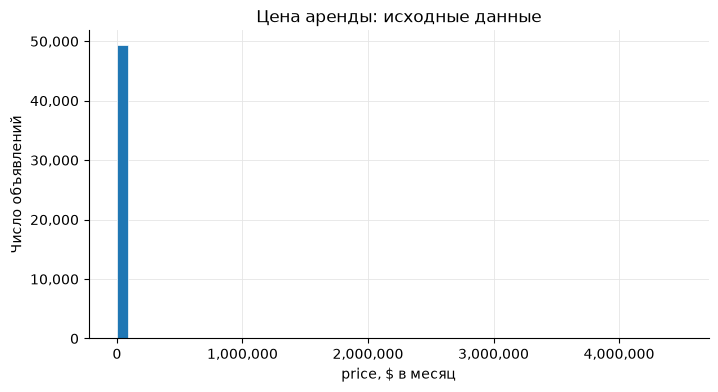

В первый столбец (до 89,842 $) попало 49344 из 49352 объявлений
Пять самых дорогих объявлений: [4490000, 1150000, 1070000, 1070000, 135000]
Асимметрия (skewness): 177.7


In [10]:
fig, ax = plt.subplots()
counts, edges, _ = ax.hist(data['price'], bins=50, edgecolor='white', linewidth=0.5)
ax.set(title='Цена аренды: исходные данные', xlabel='price, $ в месяц', ylabel='Число объявлений')
ax.xaxis.set_major_formatter(THOUSANDS)
ax.yaxis.set_major_formatter(THOUSANDS)
plt.show()

print(f'В первый столбец (до {edges[1]:,.0f} $) попало {counts[0]:.0f} из {len(data)} объявлений')
print('Пять самых дорогих объявлений:', data['price'].nlargest(5).tolist())
print(f"Асимметрия (skewness): {data['price'].skew():.1f}")

**Ответ:** нет, по такой гистограмме ничего не понять. Почти все объявления (49 344 из 49 352) попали в первый столбец шириной около 90 тысяч, а ось X растянута до 4.49 млн из-за нескольких объявлений с нереальной ценой (4 490 000, 1 150 000, дважды 1 070 000 - вероятно, лишние нули при вводе). Формы распределения не видно; асимметрия 177.7 говорит об экстремально длинном правом хвосте.

### 3.1.2. Boxplot

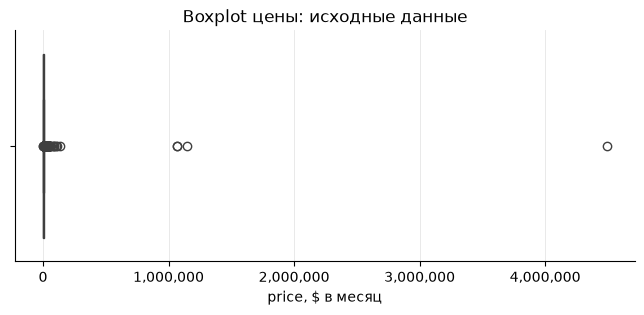

Q1 = 2500, медиана = 3150, Q3 = 4100, IQR = 1600
Границы "усов" по правилу Тьюки: от 100 до 6500
Выше верхней границы: 2786 объявлений, ниже нижней: 2
Самые дешёвые объявления: [43, 45, 401, 695, 695]


In [11]:
fig, ax = plt.subplots(figsize=(8, 3))
sns.boxplot(x=data['price'], ax=ax, color='C0', flierprops={'marker': 'o', 'markerfacecolor': 'none'})
ax.set(title='Boxplot цены: исходные данные', xlabel='price, $ в месяц')
ax.xaxis.set_major_formatter(THOUSANDS)
plt.show()

q1, median, q3 = data['price'].quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f'Q1 = {q1:.0f}, медиана = {median:.0f}, Q3 = {q3:.0f}, IQR = {iqr:.0f}')
print(f'Границы "усов" по правилу Тьюки: от {lower:.0f} до {upper:.0f}')
print(f"Выше верхней границы: {(data['price'] > upper).sum()} объявлений, ниже нижней: {(data['price'] < lower).sum()}")
print('Самые дешёвые объявления:', data['price'].nsmallest(5).tolist())

**Ответ:** да, выбросы есть, и они огромные. Ящик (от Q1 = 2500 до Q3 = 4100) сжался в черту у нуля, потому что масштаб оси задают четыре объявления дороже миллиона. По правилу Тьюки (за "усами" - выше 6500 или ниже 100) выбросов 2788: 2786 дорогих и 2 подозрительно дешёвых (43 и 45 в месяц - для аренды в Нью-Йорке это ошибка). Не все формальные выбросы - ошибки: аренда за 7-13 тысяч реальна для больших квартир. Распределение скошено вправо: медиана (3150) ближе к Q1, чем к Q3, а хвост дорогих объявлений длинный.

### 3.1.3. Удаление строк за 1-м и 99-м перцентилями

Оставляю объявления с ценой строго между 1-м и 99-м перцентилями: `p1 < price < p99`. Строки с ценой ровно на границе тоже удаляются. Если границы включить (`p1 <= price <= p99`), останется на 36 строк больше - 48 379; на выводы это не влияет.

In [12]:
p1, p99 = data['price'].quantile([0.01, 0.99])
print(f'1-й перцентиль: {p1:.0f}, 99-й перцентиль: {p99:.0f}')
print(f"Ниже p1: {(data['price'] < p1).sum()}, ровно p1: {(data['price'] == p1).sum()}, "
      f"ровно p99: {(data['price'] == p99).sum()}, выше p99: {(data['price'] > p99).sum()}")

n_before = len(data)
data = data[(data['price'] > p1) & (data['price'] < p99)].copy()
print(f'Строк было {n_before}, осталось {len(data)}, удалено {n_before - len(data)}')

1-й перцентиль: 1475, 99-й перцентиль: 13000
Ниже p1: 492, ровно p1: 15, ровно p99: 21, выше p99: 481
Строк было 49352, осталось 48343, удалено 1009


### 3.1.4. Гистограмма цены после удаления выбросов

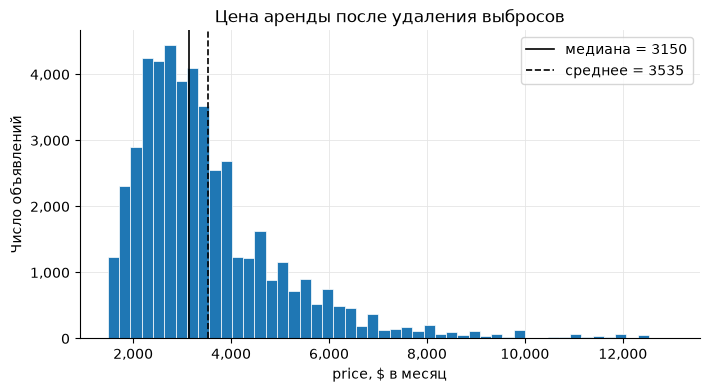

Мода: 2500, медиана: 3150, среднее: 3535, std: 1586
Половина объявлений - от 2500 до 4062
95%-й доверительный интервал для среднего: от 3521 до 3549
Асимметрия: 1.99 (до очистки 177.7); асимметрия log(price): 0.59


In [13]:
price = data['price']
fig, ax = plt.subplots()
ax.hist(price, bins=50, edgecolor='white', linewidth=0.5)
ax.axvline(price.median(), color='black', linewidth=1.2, label=f'медиана = {price.median():.0f}')
ax.axvline(price.mean(), color='black', linewidth=1.2, linestyle='--', label=f'среднее = {price.mean():.0f}')
ax.set(title='Цена аренды после удаления выбросов', xlabel='price, $ в месяц', ylabel='Число объявлений')
ax.xaxis.set_major_formatter(THOUSANDS)
ax.yaxis.set_major_formatter(THOUSANDS)
ax.legend()
plt.show()

ci_low, ci_high = sm.stats.DescrStatsW(price).tconfint_mean(alpha=0.05)
print(f'Мода: {price.mode()[0]}, медиана: {price.median():.0f}, среднее: {price.mean():.0f}, std: {price.std():.0f}')
print(f'Половина объявлений - от {price.quantile(0.25):.0f} до {price.quantile(0.75):.0f}')
print(f'95%-й доверительный интервал для среднего: от {ci_low:.0f} до {ci_high:.0f}')
print(f"Асимметрия: {price.skew():.2f} (до очистки {df['price'].skew():.1f}); асимметрия log(price): {np.log(price).skew():.2f}")

**Ответ:** теперь форма распределения видна. Оно унимодальное, с пиком около 2600-2900 (мода - 2500), половина объявлений стоит от 2500 до 4062. Распределение скошено вправо (асимметрия 2.0 вместо 177.7 до очистки): хвост дорогих квартир тянется до 13 000, поэтому среднее (3535) больше медианы (3150). Логарифм цены распределён почти симметрично (асимметрия 0.59), то есть цена похожа на логнормальную величину - это типично для цен: снизу они ограничены, сверху нет. Средняя цена оценена точно: 95%-й доверительный интервал - от 3521 до 3549, потому что объявлений много.

## 3.2. Анализ признаков
### 3.2.1. Тип столбца `interest_level`

In [14]:
print(data['interest_level'].dtype)

str


**Ответ:** тип `object` - строковый (текстовый) столбец. В pandas 3 строки по умолчанию хранятся в отдельном типе `str`, поэтому вывод выше показывает `str`; в старых версиях pandas здесь был бы `object`. По смыслу это категориальный порядковый признак: три уровня интереса к объявлению, `low` < `medium` < `high`.

### 3.2.2. Значения и их количество

In [15]:
counts = data['interest_level'].value_counts()
pd.DataFrame({'объявлений': counts, 'доля': (counts / counts.sum()).round(3)})

,объявлений,доля
interest_level,,
low,33672,0.697
medium,11114,0.230
high,3557,0.074


In [16]:
df.loc[df['price'].between(p1, p99), 'interest_level'].value_counts()

interest_level
low       33697
medium    11116
high       3566
Name: count, dtype: int64

**Ответ:** три значения - `low`, `medium`, `high`. Количество зависит от того, оставлять ли объявления с ценой ровно на границах 1-го и 99-го перцентилей:

| interest_level | границы включены (`p1 <= price <= p99`) | границы исключены (`p1 < price < p99`, как в этом ноутбуке) |
|---|---|---|
| low | 33 697 | 33 672 (69.7 %) |
| medium | 11 116 | 11 114 (23.0 %) |
| high | 3566 | 3557 (7.4 %) |

Разница - 36 объявлений с ценой ровно 1475 или 13 000. Дальше используется строгий фильтр. Классы несбалансированы: к большинству объявлений интерес низкий.

### 3.2.3. Кодирование `interest_level`

Модели работают только с числами. Признак порядковый, поэтому кодирую с сохранением порядка: `low` → 0, `medium` → 1, `high` → 2. Для категорий без порядка лучше подошло бы one-hot-кодирование.

In [17]:
data['interest_level'] = data['interest_level'].map(INTEREST_CODES)
assert data['interest_level'].notna().all() 
data['interest_level'].value_counts().sort_index()

interest_level
0    33672
1    11114
2     3557
Name: count, dtype: int64

### 3.2.4. Гистограммы `bathrooms` и `bedrooms`

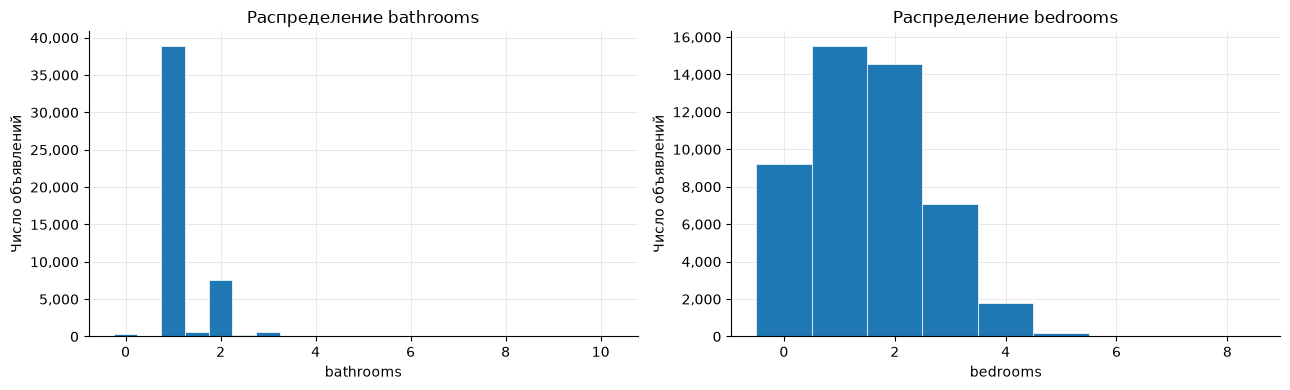

bathrooms,0.0,1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5,5.0,10.0
объявлений,302,38913,645,7571,230,564,32,83,1,1,1


bathrooms: Q1 = 1.0, Q3 = 1.0, "усы" от 1.0 до 1.0, вне "усов" 9430 строк (19.5%)


bedrooms,0,1,2,3,4,5,6,7,8
объявлений,9200,15528,14534,7055,1775,204,44,1,2


bedrooms: Q1 = 1.0, Q3 = 2.0, "усы" от -0.5 до 3.5, вне "усов" 2026 строк (4.2%)


,bathrooms,bedrooms,interest_level,price
104459,10.0,2,0,3600


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, step in zip(axes, ['bathrooms', 'bedrooms'], [0.5, 1]):
    bins = np.arange(data[col].min() - step / 2, data[col].max() + step, step)
    ax.hist(data[col], bins=bins, edgecolor='white', linewidth=0.5)
    ax.set(title=f'Распределение {col}', xlabel=col, ylabel='Число объявлений')
    ax.yaxis.set_major_formatter(THOUSANDS)
plt.tight_layout()
plt.show()

for col in ['bathrooms', 'bedrooms']:
    display(data[col].value_counts().sort_index().to_frame('объявлений').T)
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((data[col] < q1 - 1.5 * iqr) | (data[col] > q3 + 1.5 * iqr)).sum()
    print(f'{col}: Q1 = {q1}, Q3 = {q3}, "усы" от {q1 - 1.5 * iqr} до {q3 + 1.5 * iqr}, '
          f'вне "усов" {n_out} строк ({n_out / len(data):.1%})')

display(data[data['bathrooms'] == 10])

**Ответ:** значимых выбросов, которые нужно удалять, нет. Оба признака дискретные, и большие значения - в основном реальные большие квартиры.
- `bathrooms`: у 80 % квартир одна ванная. Правило Тьюки здесь не подходит: Q1 = Q3 = 1, IQR = 0, и "выбросом" формально оказывается любое значение, кроме 1, - 9430 строк (19.5 %). Единственная подозрительная строка - 10 ванных в квартире с двумя спальнями за 3600 в месяц (последняя таблица; скорее всего, опечатка вместо 1.0). Ещё 302 объявления с нулём ванных - скорее пропуск в данных.
- `bedrooms`: по правилу Тьюки (больше 3.5) формально выходят 2026 квартир с 4 и более спальнями, но это реальные большие квартиры. Редки только 7 и 8 спален (3 объявления). Ноль спален - студии (9200 объявлений), это не ошибка.

## 3.3. Комплексный анализ
### 3.3.1. Корреляционная матрица и heat map

,bathrooms,bedrooms,interest_level,price
bathrooms,1.000000,0.517200,-0.062819,0.670808
bedrooms,0.517200,1.000000,0.051282,0.547310
interest_level,-0.062819,0.051282,1.000000,-0.199652
price,0.670808,0.547310,-0.199652,1.000000


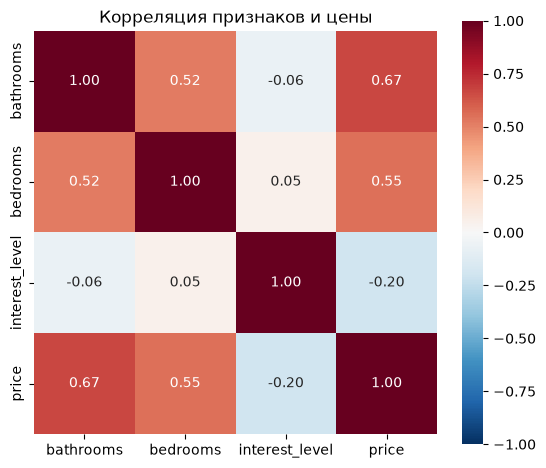

In [19]:
corr = data.corr()
display(corr)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title('Корреляция признаков и цены')
plt.show()

In [20]:
features3 = ['bathrooms', 'bedrooms', 'interest_level']
pd.DataFrame(
    [(*st.pearsonr(data[col], data['price']), *st.spearmanr(data[col], data['price'])) for col in features3],
    index=features3, columns=['pearson_r', 'pearson_p', 'spearman_r', 'spearman_p'])

,pearson_r,pearson_p,spearman_r,spearman_p
bathrooms,0.670808,0.0,0.544559,0.0
bedrooms,0.547310,0.0,0.563761,0.0
interest_level,-0.199652,0.0,-0.221673,0.0


**Ответ:** да, корреляция есть, и после удаления выбросов она намного сильнее, чем в п. 2.4:
- `bathrooms` и `price`: 0.67 - самая сильная связь, положительная: чем больше ванных, тем дороже квартира;
- `bedrooms` и `price`: 0.55 - умеренная положительная;
- `interest_level` и `price`: −0.20 - слабая отрицательная: к дорогим объявлениям интерес ниже;
- между собой `bathrooms` и `bedrooms` связаны умеренно (0.52) и частично дублируют друг друга; `interest_level` с ними почти не связан (−0.06 и 0.05).

Все три связи статистически значимы: p-value практически 0 - при 48 тысячах объектов значима даже слабая связь. Ранговая корреляция Спирмена у `bathrooms` ниже (0.54): у 80 % квартир одна ванная, и одинаковых значений много.

### 3.3.2. Scatterplot: цена и признаки

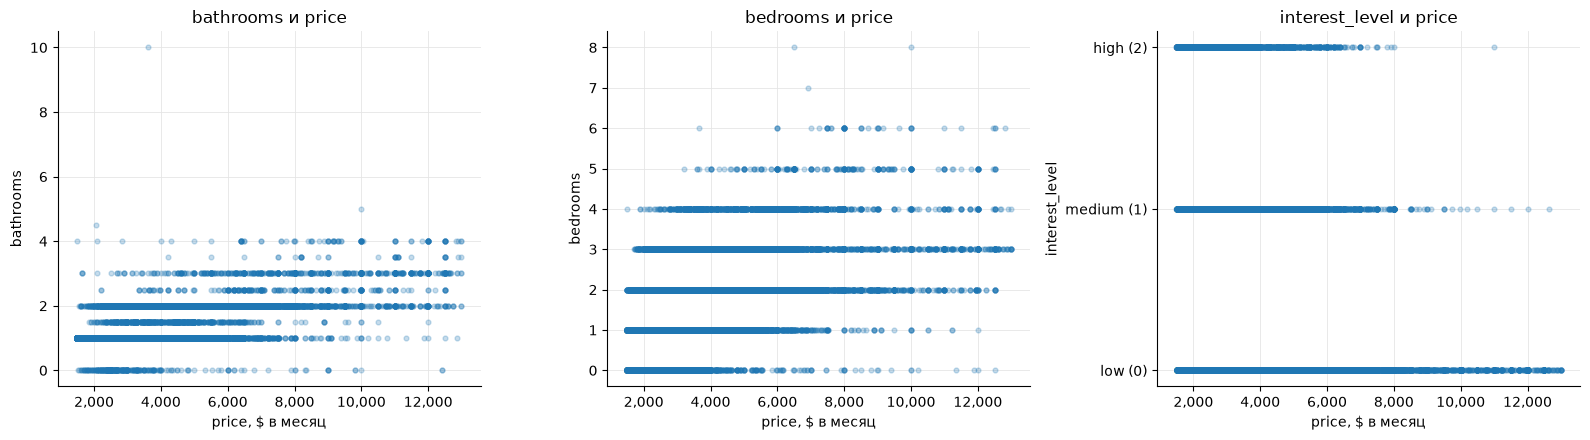

bathrooms,0.0,1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5,5.0,10.0
count,302.0,38913.0,645.0,7571.0,230.0,564.0,32.0,83.0,1.0,1.0,1.0
median,2700.0,2900.0,4240.0,5200.0,7425.0,8500.0,11000.0,9300.0,2050.0,9995.0,3600.0


bedrooms,0,1,2,3,4,5,6,7,8
count,9200.0,15528.0,14534.0,7055.0,1775.0,204.0,44.0,1.0,2.0
median,2450.0,2950.0,3350.0,4495.0,5795.0,7781.5,8000.0,6923.0,8247.5


interest_level,0,1,2
count,33672.0,11114.0,3557.0
median,3300.0,2895.0,2500.0


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, features3):
    ax.scatter(data['price'], data[col], alpha=0.25, s=12)
    ax.set(title=f'{col} и price', xlabel='price, $ в месяц', ylabel=col)
    ax.xaxis.set_major_formatter(THOUSANDS)
axes[2].set_yticks([0, 1, 2], ['low (0)', 'medium (1)', 'high (2)'])
plt.tight_layout()
plt.show()

for col in features3:
    display(data.groupby(col)['price'].agg(['count', 'median']).T)

**Ответ.** Точки выстроены горизонтальными "полосами", потому что признаки дискретные. Что видно:
- `bathrooms`: полоса "одна ванная" плотная до 6000 и почти обрывается дальше (дороже 6000 - меньше 1 % таких квартир), а квартиры с тремя и более ваннами редко бывают дешевле 4000 (4 % из них). Медианная цена растёт с числом ванных: 2900 при одной, 5200 при двух, 8500 при трёх. Видна и аномалия - точка с 10 ваннами при цене 3600.
- `bedrooms`: с ростом числа спален полосы сдвигаются вправо: медиана 2450 у студий, 2950 при одной спальне, 3350 при двух, 4495 при трёх, 5795 при четырёх.
- `interest_level`: высокий интерес собирают в основном недорогие объявления (медиана 2500 против 3300 при низком интересе), полоса `high` редеет к правому краю.

Внутри каждой полосы цены различаются в несколько раз, поэтому одними `bathrooms` и `bedrooms` цену точно не предсказать - важны район, площадь, состояние квартиры.

# 4. Creating Features
## 4.1. Квадраты признаков

,bathrooms,bedrooms,interest_level,price,bathrooms_squared,bedrooms_squared,interest_level_squared
bathrooms,1.000000,0.517200,-0.062819,0.670808,0.955906,0.548426,-0.058710
bedrooms,0.517200,1.000000,0.051282,0.547310,0.478497,0.928282,0.040125
interest_level,-0.062819,0.051282,1.000000,-0.199652,-0.067757,0.047048,0.943959
price,0.670808,0.547310,-0.199652,1.000000,0.646949,0.544612,-0.182283
bathrooms_squared,0.955906,0.478497,-0.067757,0.646949,1.000000,0.521951,-0.061563
bedrooms_squared,0.548426,0.928282,0.047048,0.544612,0.521951,1.000000,0.036408
interest_level_squared,-0.058710,0.040125,0.943959,-0.182283,-0.061563,0.036408,1.000000


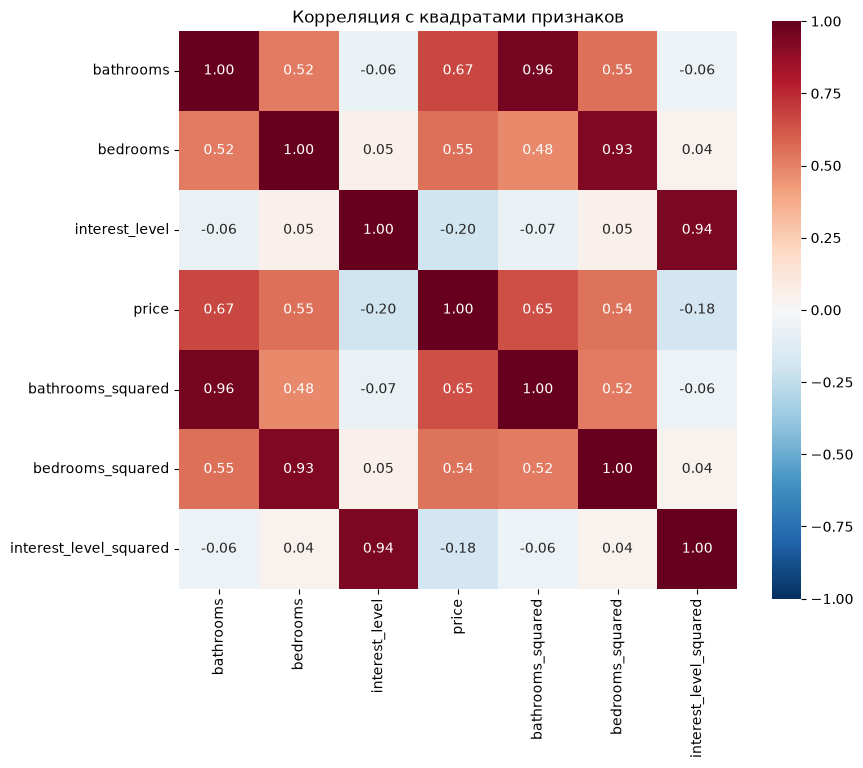

In [22]:
data_sq = data.copy() 
for col in features3:
    data_sq[f'{col}_squared'] = data_sq[col] ** 2

corr_sq = data_sq.corr()
display(corr_sq)

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr_sq, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title('Корреляция с квадратами признаков')
plt.show()

In [23]:
comparison = pd.DataFrame({
    'corr с price': [corr_sq.loc[col, 'price'] for col in features3],
    'corr квадрата с price': [corr_sq.loc[f'{col}_squared', 'price'] for col in features3],
    'corr квадрата с признаком': [corr_sq.loc[f'{col}_squared', col] for col in features3],
}, index=features3)
comparison['квадрат сильнее связан с price?'] = comparison['corr квадрата с price'].abs() > comparison['corr с price'].abs()
display(comparison.round(3))

,corr с price,corr квадрата с price,corr квадрата с признаком,квадрат сильнее связан с price?
bathrooms,0.671,0.647,0.956,False
bedrooms,0.547,0.545,0.928,False
interest_level,-0.200,-0.182,0.944,False


**Ответ:** нет. Квадраты связаны с ценой чуть *слабее* исходных признаков: `bathrooms` 0.671 → 0.647, `bedrooms` 0.547 → 0.545, `interest_level` −0.200 → −0.182 (по модулю меньше). При этом квадраты почти повторяют исходные признаки (корреляция с ними 0.96, 0.93 и 0.94), то есть новой информации почти не несут. Причина: на малых неотрицательных значениях x² - монотонное и почти линейное преобразование, которое лишь растягивает редкие большие значения (10 ванных → 100), а это шум для линейной связи. Корреляция Пирсона измеряет только линейную связь, поэтому пользу нелинейных признаков надо проверять по качеству моделей.

## 4.2. Признаки для обучения

Новые признаки при обучении не используем (вернёмся к ним в Lecture 2). Модели обучаем только на `bathrooms` и `bedrooms`.

## 4.3. PolynomialFeatures

`PolynomialFeatures(degree=d)` строит все одночлены от исходных признаков степени не выше d: столбец единиц, сами признаки, их степени и произведения. Для двух признаков a, b и d = 2 это `1, a, b, a², ab, b²`; для d = 10 - C(12, 2) = 66 столбцов, вплоть до `a¹⁰` и `a·b⁹`. Так линейная модель может описывать нелинейные зависимости. Но масштабы столбцов различаются на много порядков (у объявления с 10 ваннами `bathrooms¹⁰` = 10¹⁰), а при большой степени модель легко переобучается.

## 4.4. Обучающая и тестовая выборки

Готовых файлов с разбиением у меня не было, есть только `train.json` с Kaggle. Разбиение делаю через `train_test_split` с долей теста по умолчанию (`test_size=0.25`) и `random_state=1`, применённый к очищенному датафрейму из п. 3.1.3.

In [24]:
train, test = train_test_split(data, test_size=0.25, random_state=1)
train, test = train.copy(), test.copy()

features = ['bathrooms', 'bedrooms']
X_train, y_train = train[features], train['price']
X_test, y_test = test[features], test['price']
print(f'train: {len(train)} строк, test: {len(test)} строк')

train: 36257 строк, test: 12086 строк


## 4.5-4.6. PolynomialFeatures степени 10

In [25]:
poly = PolynomialFeatures(degree=10)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print('Размер после преобразования: train', X_train_poly.shape, ', test', X_test_poly.shape)
print('Первые столбцы:', list(poly.get_feature_names_out()[:8]))
print(f'Максимальное значение в матрице признаков: {X_train_poly.max():.0e}')

Размер после преобразования: train (36257, 66) , test (12086, 66)
Первые столбцы: ['1', 'bathrooms', 'bedrooms', 'bathrooms^2', 'bathrooms bedrooms', 'bedrooms^2', 'bathrooms^3', 'bathrooms^2 bedrooms']
Максимальное значение в матрице признаков: 1e+10


# 5. Models
## 5.1. Таблицы результатов

In [26]:
result_MAE = pd.DataFrame(columns=['model', 'train', 'test']).astype({'train': float, 'test': float})
result_RMSE = pd.DataFrame(columns=['model', 'train', 'test']).astype({'train': float, 'test': float})
result_MAE

,model,train,test


## 5.2. Линейная регрессия

In [27]:
linreg = LinearRegression()
linreg.fit(X_train_poly, y_train)

train['pred_linreg'] = linreg.predict(X_train_poly)
test['pred_linreg'] = linreg.predict(X_test_poly)

mae_train = mean_absolute_error(y_train, train['pred_linreg'])
mae_test = mean_absolute_error(y_test, test['pred_linreg'])
rmse_train = rmse(y_train, train['pred_linreg'])
rmse_test = rmse(y_test, test['pred_linreg'])

result_MAE.loc[len(result_MAE)] = ['linear_regression', mae_train, mae_test]
result_RMSE.loc[len(result_RMSE)] = ['linear_regression', rmse_train, rmse_test]

print(f'MAE:  train {mae_train:.1f}, test {mae_test:.1f}')
print(f'RMSE: train {rmse_train:.1f}, test {rmse_test:.1f}')
print(f'Ранг решения: {linreg.rank_} из {X_train_poly.shape[1]} столбцов (sklearn {sklearn.__version__})')

MAE:  train 846.8, test 865.4
RMSE: train 1203.4, test 1259.1
Ранг решения: 18 из 66 столбцов (sklearn 1.9.1)


Ошибки на train и test почти одинаковые - переобучения нет, но модель слабая. Причина - плохая обусловленность: столбцы полиномиальных признаков отличаются по масштабу до 10¹⁰ раз и линейно зависимы (у двух признаков в train всего 50 разных комбинаций значений, а столбцов 66). Начиная с версии 1.9 sklearn при решении МНК отбрасывает направления с сингулярными числами меньше 10⁻⁶ от максимального (параметр `tol`), и модель использует лишь часть столбцов - ранг в выводе выше. В версиях до 1.9 отсечения не было: модель точно проходила через средние цены 50 комбинаций из train и давала огромные ошибки на комбинациях, которых в train нет (п. 5.5.3).

## 5.3. Решающее дерево

In [28]:
tree = DecisionTreeRegressor(random_state=21)
tree.fit(X_train_poly, y_train)

train['pred_tree'] = tree.predict(X_train_poly)
test['pred_tree'] = tree.predict(X_test_poly)

mae_train = mean_absolute_error(y_train, train['pred_tree'])
mae_test = mean_absolute_error(y_test, test['pred_tree'])
rmse_train = rmse(y_train, train['pred_tree'])
rmse_test = rmse(y_test, test['pred_tree'])

result_MAE.loc[len(result_MAE)] = ['decision_tree', mae_train, mae_test]
result_RMSE.loc[len(result_RMSE)] = ['decision_tree', rmse_train, rmse_test]

print(f'MAE:  train {mae_train:.1f}, test {mae_test:.1f}')
print(f'RMSE: train {rmse_train:.1f}, test {rmse_test:.1f}')
print(f'Листьев в дереве: {tree.get_n_leaves()}, разных комбинаций (bathrooms, bedrooms) в train: {len(X_train.drop_duplicates())}')

MAE:  train 750.8, test 763.2
RMSE: train 1068.6, test 1079.8
Листьев в дереве: 50, разных комбинаций (bathrooms, bedrooms) в train: 50


Дерево без ограничения глубины разбило train на листья - по одному на каждую комбинацию (`bathrooms`, `bedrooms`) - и в каждом листе предсказывает среднюю цену этой комбинации. Точнее по квадратичной ошибке на train из двух признаков не предсказать, поэтому ошибка на train ниже, чем у линейной регрессии. Разница между train и test маленькая: признаки грубые (всего 50 разных точек), и переобучаться дереву не на чем.

## 5.4. Наивные модели

Наивная модель игнорирует признаки и всем объектам предсказывает одну константу - среднее или медиану цены. Константу считаем по обучающей выборке и используем и для train, и для test: при прогнозе цены теста неизвестны.

In [29]:
print(f'Для справки - test: среднее {y_test.mean():.1f}, медиана {y_test.median():.1f} (в прогнозе не используются)')

for name, value in [('naive_mean', y_train.mean()), ('naive_median', y_train.median())]:
    train[name] = value 
    test[name] = value

    mae_train = mean_absolute_error(y_train, train[name])
    mae_test = mean_absolute_error(y_test, test[name])
    rmse_train = rmse(y_train, train[name])
    rmse_test = rmse(y_test, test[name])

    result_MAE.loc[len(result_MAE)] = [name, mae_train, mae_test]
    result_RMSE.loc[len(result_RMSE)] = [name, rmse_train, rmse_test]
    print(f'{name}: прогноз {value:.1f}; MAE train {mae_train:.6f}, test {mae_test:.6f}; '
          f'RMSE train {rmse_train:.6f}, test {rmse_test:.6f}')

Для справки - test: среднее 3554.2, медиана 3150.0 (в прогнозе не используются)
naive_mean: прогноз 3528.8; MAE train 1124.770343, test 1156.350670; RMSE train 1572.875395, test 1623.259518
naive_median: прогноз 3150.0; MAE train 1073.794274, test 1107.499917; RMSE train 1617.851788, test 1672.633572


## 5.5. Сравнение результатов
### 5.5.1. Итоговые таблицы

In [30]:
display(result_MAE)
display(result_RMSE)

for metric, table in [('MAE', result_MAE), ('RMSE', result_RMSE)]:
    best = table.loc[table['test'].idxmin()]
    print(f"Лучшая модель по {metric} на test: {best['model']} ({best['test']:.1f})")

,model,train,test
0,linear_regression,846.825650,865.385796
1,decision_tree,750.818253,763.239547
2,naive_mean,1124.770343,1156.350670
3,naive_median,1073.794274,1107.499917


,model,train,test
0,linear_regression,1203.405424,1259.133564
1,decision_tree,1068.629884,1079.819506
2,naive_mean,1572.875395,1623.259518
3,naive_median,1617.851788,1672.633572


Лучшая модель по MAE на test: decision_tree (763.2)
Лучшая модель по RMSE на test: decision_tree (1079.8)


### 5.5.2. Какая модель лучшая

**Ответ: решающее дерево** - у него самые маленькие ошибки на тестовой выборке: MAE 763 и RMSE 1080. Это на 31 % меньше MAE лучшей наивной модели (медианы, 1107). Сравниваем по test, потому что он показывает качество на новых данных.

Почему полином 10-й степени опасен: точное решение МНК проходит через средние цены всех комбинаций признаков из train, а за их пределами полином "улетает". Это видно на трёх тестовых квартирах с комбинациями, которых нет в train:

In [32]:
linreg_exact = exact_linear_regression().fit(X_train_poly, y_train)
seen_combos = set(zip(X_train['bathrooms'], X_train['bedrooms']))
is_new_combo = np.array([combo not in seen_combos for combo in zip(X_test['bathrooms'], X_test['bedrooms'])])

new_combos = test.loc[is_new_combo, ['bathrooms', 'bedrooms', 'price', 'pred_tree', 'pred_linreg']].copy()
new_combos['pred_linreg_sklearn<1.9'] = linreg_exact.predict(X_test_poly[is_new_combo])
pred_cols = ['pred_tree', 'pred_linreg', 'pred_linreg_sklearn<1.9']
new_combos[pred_cols] = new_combos[pred_cols].round().astype(int)
display(new_combos)

pred_exact_train = linreg_exact.predict(X_train_poly)
pred_exact_test = linreg_exact.predict(X_test_poly)
print(f'LinearRegression как в sklearn < 1.9: MAE train {mean_absolute_error(y_train, pred_exact_train):.1f}, '
      f'test {mean_absolute_error(y_test, pred_exact_test):.1f}; RMSE test {rmse(y_test, pred_exact_test):.1f}')

,bathrooms,bedrooms,price,pred_tree,pred_linreg,pred_linreg_sklearn<1.9
104687,3.0,7,6923,9871,37477,572359
18173,3.5,2,11000,8462,10548,-4616
28722,3.0,8,9995,9871,-4524,10461123


LinearRegression как в sklearn < 1.9: MAE train 750.8, test 1675.6; RMSE test 95210.5


Точное решение МНК на train совпадает с деревом (MAE 750.8 - средние цены комбинаций), но для квартиры с 3 ваннами и 8 спальнями предсказывает больше 10 млн, и MAE на test вырастает до 1676 - хуже наивных моделей. Решающее дерево так не ошибается: для незнакомой комбинации оно отдаёт среднюю цену одного из своих листьев, поэтому прогноз всегда остаётся в диапазоне цен из train.

## 5.6. Дополнительно: все данные объявления и градиентный бустинг

Те же строки train и test, но с признаками из всего объявления: координаты, число фото и удобств, длина описания, дата публикации, частота здания и менеджера в данных, 30 самых частых удобств. Всё, что вычисляется по данным (частоты, список удобств), считаю только по train, чтобы не подглядывать в test. Модель - LightGBM; число деревьев подбирается ранней остановкой на валидационной части train (15 %).

In [33]:
full = df.loc[data.index].copy()
full['interest_level'] = full['interest_level'].map(INTEREST_CODES)
full['n_photos'] = full['photos'].apply(len)
full['n_features'] = full['features'].apply(len)
full['desc_words'] = full['description'].str.split().apply(len)
created = pd.to_datetime(full['created'])
full['month'] = created.dt.month
full['day'] = created.dt.day
full['hour'] = created.dt.hour
full['weekday'] = created.dt.dayofweek

for col in ['building_id', 'manager_id']:
    full[f'{col}_count'] = full[col].map(full.loc[train.index, col].value_counts()).fillna(0)
full.loc[full['building_id'] == '0', 'building_id_count'] = 0  

amenities = full['features'].apply(lambda items: {item.strip().lower() for item in items})
top_amenities = pd.Series([a for items in amenities.loc[train.index] for a in items]).value_counts().index[:30]
amenity_cols = []
for amenity in top_amenities:
    col = 'has_' + re.sub(r'\W+', '_', amenity)
    full[col] = amenities.apply(lambda items: amenity in items).astype(int)
    amenity_cols.append(col)

feat_all = ['bathrooms', 'bedrooms', 'interest_level', 'latitude', 'longitude', 'n_photos', 'n_features',
            'desc_words', 'month', 'day', 'hour', 'weekday', 'building_id_count', 'manager_id_count'] + amenity_cols
X_full_train, X_full_test = full.loc[train.index, feat_all], full.loc[test.index, feat_all]
print(f'Признаков: {len(feat_all)}')

Признаков: 44


In [34]:
X_fit, X_valid, y_fit, y_valid = train_test_split(X_full_train, y_train, test_size=0.15, random_state=21)

params = {'objective': 'regression', 'metric': 'l1', 'learning_rate': 0.05, 'num_leaves': 63,
          'bagging_fraction': 0.8, 'bagging_freq': 1, 'feature_fraction': 0.8, 'seed': 21, 'verbose': -1}
gbm = lgb.train(params, lgb.Dataset(X_fit, y_fit), num_boost_round=3000,
                valid_sets=[lgb.Dataset(X_valid, y_valid)],
                callbacks=[lgb.early_stopping(200, verbose=False)])
print('Деревьев после ранней остановки:', gbm.best_iteration) 

linreg_deg1 = LinearRegression().fit(X_train, y_train)

extra = {
    'linear_regression_degree1': (linreg_deg1.predict(X_train), linreg_deg1.predict(X_test)),
    'lightgbm_all_features': (gbm.predict(X_full_train), gbm.predict(X_full_test)),
}
result_MAE_ext, result_RMSE_ext = result_MAE.copy(), result_RMSE.copy()
for name, (p_tr, p_te) in extra.items():
    result_MAE_ext.loc[len(result_MAE_ext)] = [name, mean_absolute_error(y_train, p_tr), mean_absolute_error(y_test, p_te)]
    result_RMSE_ext.loc[len(result_RMSE_ext)] = [name, rmse(y_train, p_tr), rmse(y_test, p_te)]
display(result_MAE_ext)
display(result_RMSE_ext)

Деревьев после ранней остановки: 2925


,model,train,test
0,linear_regression,846.825650,865.385796
1,decision_tree,750.818253,763.239547
2,naive_mean,1124.770343,1156.350670
3,naive_median,1073.794274,1107.499917
4,linear_regression_degree1,778.853972,789.286714
5,lightgbm_all_features,133.237824,352.627851


,model,train,test
0,linear_regression,1203.405424,1259.133564
1,decision_tree,1068.629884,1079.819506
2,naive_mean,1572.875395,1623.259518
3,naive_median,1617.851788,1672.633572
4,linear_regression_degree1,1112.813732,1124.902320
5,lightgbm_all_features,253.887950,591.616382


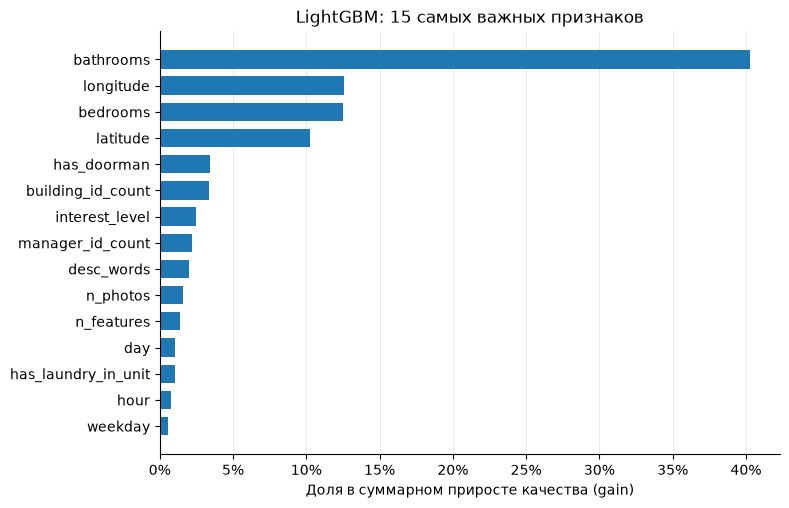

Координаты (latitude + longitude) вместе: 22.9%


,bathrooms,longitude,bedrooms,latitude,has_doorman,building_id_count,interest_level,manager_id_count
доля gain,40.3%,12.6%,12.5%,10.2%,3.4%,3.4%,2.5%,2.2%


In [35]:
importance = pd.Series(gbm.feature_importance(importance_type='gain'), index=feat_all)
importance = (importance / importance.sum()).sort_values(ascending=False)

top15 = importance.head(15).sort_values()
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top15.index, top15.values, height=0.7)
ax.set(title='LightGBM: 15 самых важных признаков', xlabel='Доля в суммарном приросте качества (gain)')
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.grid(axis='y', visible=False)
plt.show()

print(f"Координаты (latitude + longitude) вместе: {importance[['latitude', 'longitude']].sum():.1%}")
importance.head(8).map('{:.1%}'.format).to_frame('доля gain').T

**Вывод.** Бустинг на всех данных объявления снижает ошибку на test более чем вдвое: MAE 353 против 763 у дерева на двух признаках, RMSE 592 против 1080. Главные признаки по-прежнему `bathrooms` (40 % прироста качества) и `bedrooms` (12.5 %), но координаты вместе дают ещё 23 % - район сильно влияет на цену, а в двух признаках его нет. Дальше идут консьерж (`has_doorman`), число объявлений в том же здании и у того же менеджера, `interest_level`. Разрыв между train (133) и test (353) показывает, что модель частично запоминает обучающую выборку, но на новых данных она всё равно намного точнее остальных. Заодно видно, что обычная линейная регрессия на двух исходных признаках (MAE 789 на test) лучше полиномиальной степени 10 (865).